# CNN-GRU

Model implementation intentionally omitted from the public repository.


shape train:: torch.Size([91978, 60, 6]) torch.Size([91978, 1])
shape test:: torch.Size([11498, 60, 6]) torch.Size([11498, 1])
Epoch 01/30 | Train Loss: 0.000006 (30.618s) | Val Loss: 0.000005 (1.654s)
Epoch 02/30 | Train Loss: 0.000004 (29.498s) | Val Loss: 0.000005 (1.803s)
Epoch 03/30 | Train Loss: 0.000003 (32.147s) | Val Loss: 0.000003 (1.890s)
Epoch 04/30 | Train Loss: 0.000003 (34.163s) | Val Loss: 0.000002 (2.153s)
Epoch 05/30 | Train Loss: 0.000003 (37.699s) | Val Loss: 0.000002 (2.103s)
Epoch 06/30 | Train Loss: 0.000003 (37.393s) | Val Loss: 0.000002 (2.247s)
Epoch 07/30 | Train Loss: 0.000003 (38.661s) | Val Loss: 0.000002 (2.285s)
Epoch 08/30 | Train Loss: 0.000002 (38.897s) | Val Loss: 0.000003 (2.288s)
Epoch 09/30 | Train Loss: 0.000002 (38.175s) | Val Loss: 0.000002 (2.384s)
Epoch 10/30 | Train Loss: 0.000002 (39.764s) | Val Loss: 0.000003 (2.358s)
Epoch 11/30 | Train Loss: 0.000002 (38.577s) | Val Loss: 0.000002 (2.353s)
Epoch 12/30 | Train Loss: 0.000002 (40.012s) | V

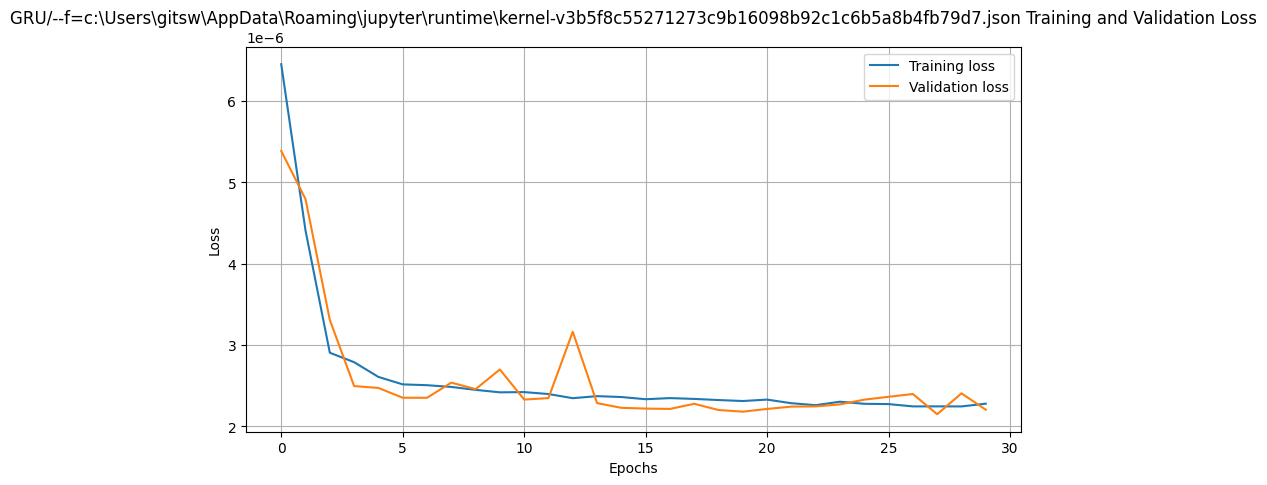

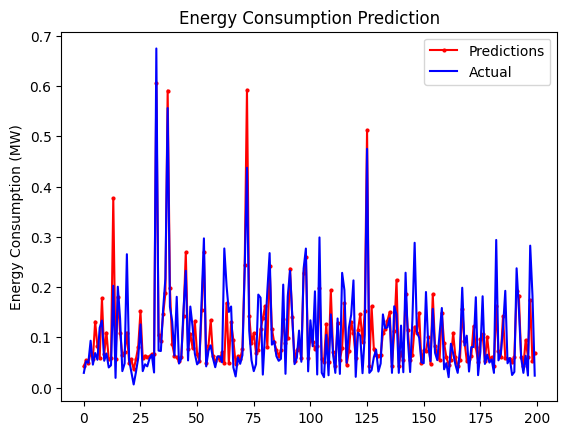

In [84]:
## GRU without k fold
#print("singleDF", sdf.describe())
train_seq, test_seq, valid_seq = divide_sequences(X, Y)
feature_len = train_seq[0].shape[2]
print("shape train::", train_seq[0].shape, train_seq[1].shape)
print("shape test::", test_seq[0].shape, test_seq[1].shape)
gru_model = GRUModel(feature_len, batch_size=1024, num_layers=20, hidden_size=128, iteration_name=it_name,cnn=True,cnn_ol=15, lr=0.001, reg=1e-6, epochs=30)
gru_model.run_model(train_seq, test_seq, valid_seq)

In [85]:
!nvidia-smi

Mon Oct  5 20:27:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.79                 Driver Version: 595.79         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4070 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   79C    P4             11W /   55W |    6973MiB /   8188MiB |     19%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [86]:
torch.cuda.is_available()

True

In [87]:
print("started kf")
train_seq, test_seq = divide_sequences_cf(X, Y)
feature_len = train_seq[0].shape[2]
print("shape train::", train_seq[0].shape, train_seq[1].shape)
print("shape test::", test_seq[0].shape, test_seq[1].shape)


started kf
shape train:: torch.Size([103475, 60, 6]) torch.Size([103475, 1])
shape test:: torch.Size([11498, 60, 6]) torch.Size([11498, 1])


Epoch 01/30 | Train Loss: 0.000009 (43.740s) | Val Loss: 0.000008 (2.265s)
Epoch 02/30 | Train Loss: 0.000007 (46.013s) | Val Loss: 0.000005 (2.083s)
Epoch 03/30 | Train Loss: 0.000005 (34.414s) | Val Loss: 0.000004 (2.698s)
Epoch 04/30 | Train Loss: 0.000004 (32.602s) | Val Loss: 0.000004 (1.914s)
Epoch 05/30 | Train Loss: 0.000004 (33.062s) | Val Loss: 0.000004 (1.638s)
Epoch 06/30 | Train Loss: 0.000004 (32.078s) | Val Loss: 0.000004 (1.777s)
Epoch 07/30 | Train Loss: 0.000004 (32.852s) | Val Loss: 0.000004 (1.123s)
Epoch 08/30 | Train Loss: 0.000004 (30.455s) | Val Loss: 0.000004 (1.127s)
Epoch 09/30 | Train Loss: 0.000004 (30.570s) | Val Loss: 0.000004 (1.133s)
Epoch 10/30 | Train Loss: 0.000004 (25.854s) | Val Loss: 0.000004 (0.899s)
Epoch 11/30 | Train Loss: 0.000004 (20.665s) | Val Loss: 0.000004 (0.786s)
Epoch 12/30 | Train Loss: 0.000004 (19.737s) | Val Loss: 0.000003 (0.771s)
Epoch 13/30 | Train Loss: 0.000004 (19.710s) | Val Loss: 0.000003 (0.779s)
Epoch 14/30 | Train Loss:

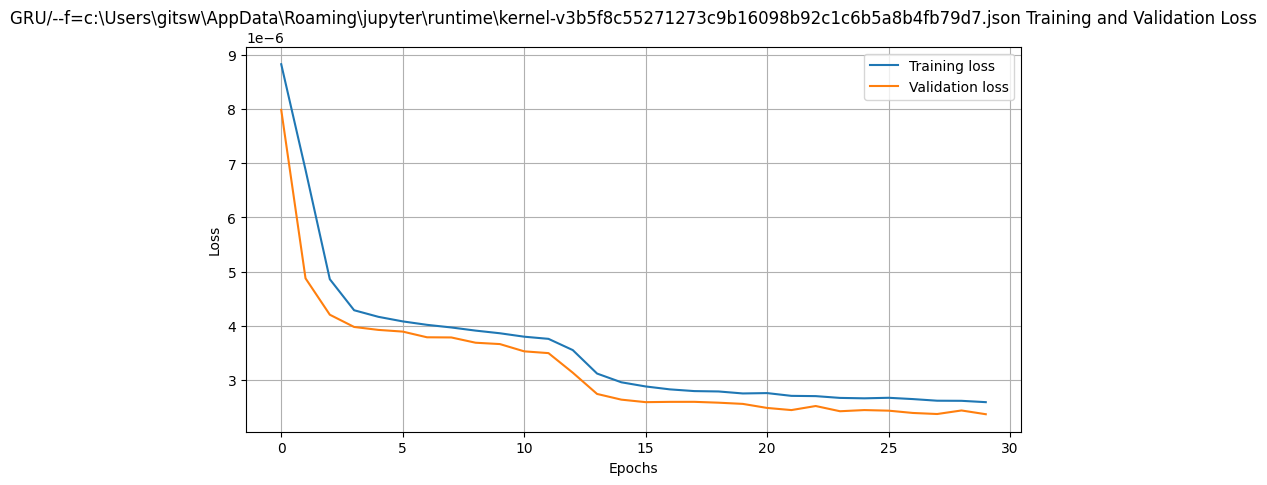

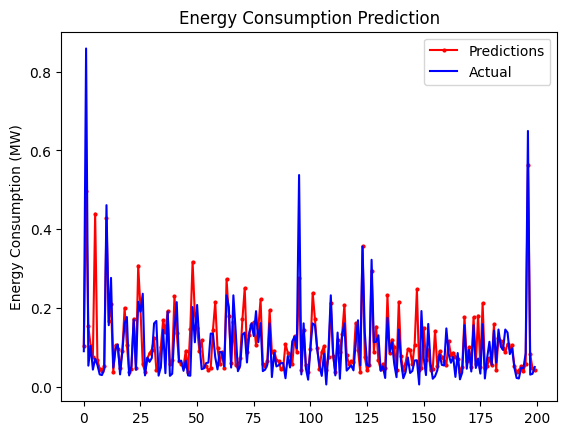

In [88]:
gru_model_kf = GRUModel(feature_len, batch_size=1024, num_layers=20, hidden_size=128, iteration_name=it_name,cnn=True,cnn_ol=10, lr=0.0001, reg=1e-6, epochs=30)

gru_model_kf.run_model(train_seq, test_seq, test_seq)

In [89]:
from torchsummary import summary
summary(gru_model.model, input_size=(60, 6))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv1d-1               [-1, 15, 60]             285
       BatchNorm1d-2               [-1, 15, 60]              30
              ReLU-3               [-1, 15, 60]               0
         MaxPool1d-4               [-1, 15, 59]               0
            Conv1d-5               [-1, 15, 59]             690
       BatchNorm1d-6               [-1, 15, 59]              30
              ReLU-7               [-1, 15, 59]               0
         MaxPool1d-8               [-1, 15, 58]               0
               GRU-9  [[-1, 58, 128], [-1, 2, 128]]               0
             ReLU-10                  [-1, 128]               0
           Linear-11                    [-1, 1]             129
Total params: 1,164
Trainable params: 1,164
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/

114973
60
6
torch.Size([114973, 60, 3])
shape train:: torch.Size([91978, 60, 3]) torch.Size([91978, 1])
shape test:: torch.Size([11498, 60, 3]) torch.Size([11498, 1])
Epoch 01/30 | Train Loss: 0.000009 (26.820s) | Val Loss: 0.000008 (1.123s)
Epoch 02/30 | Train Loss: 0.000008 (26.665s) | Val Loss: 0.000008 (1.105s)
Epoch 03/30 | Train Loss: 0.000008 (26.795s) | Val Loss: 0.000008 (1.124s)
Epoch 04/30 | Train Loss: 0.000008 (26.717s) | Val Loss: 0.000008 (1.141s)
Epoch 05/30 | Train Loss: 0.000008 (26.966s) | Val Loss: 0.000008 (1.132s)
Epoch 06/30 | Train Loss: 0.000008 (25.337s) | Val Loss: 0.000008 (0.987s)
Epoch 07/30 | Train Loss: 0.000008 (18.784s) | Val Loss: 0.000008 (0.799s)
Epoch 08/30 | Train Loss: 0.000008 (17.503s) | Val Loss: 0.000008 (0.801s)
Epoch 09/30 | Train Loss: 0.000008 (17.794s) | Val Loss: 0.000008 (0.800s)
Epoch 10/30 | Train Loss: 0.000008 (17.670s) | Val Loss: 0.000008 (0.780s)
Epoch 11/30 | Train Loss: 0.000008 (17.422s) | Val Loss: 0.000008 (0.832s)
Epoch 12

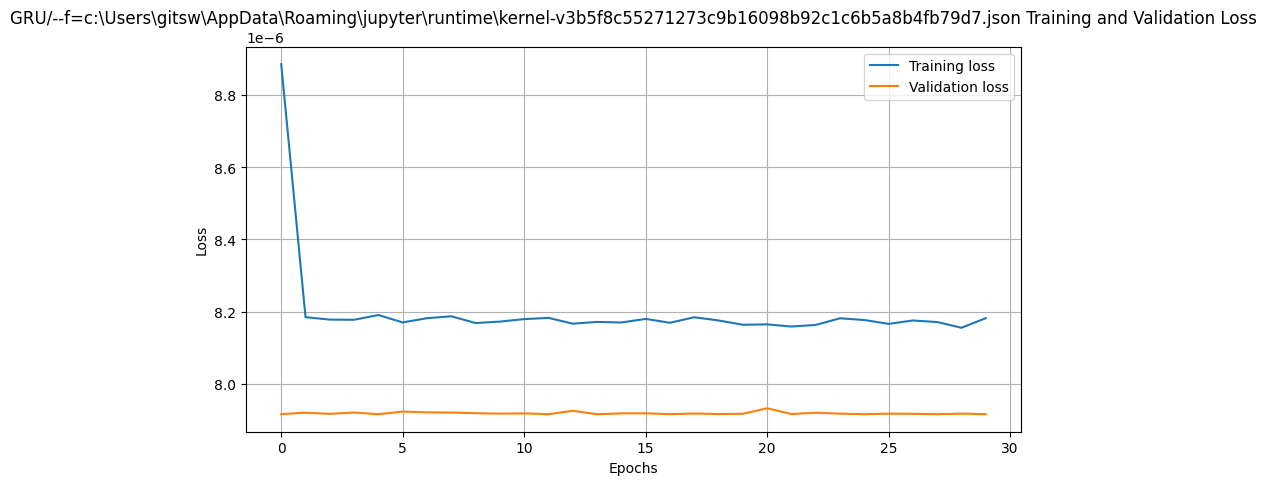

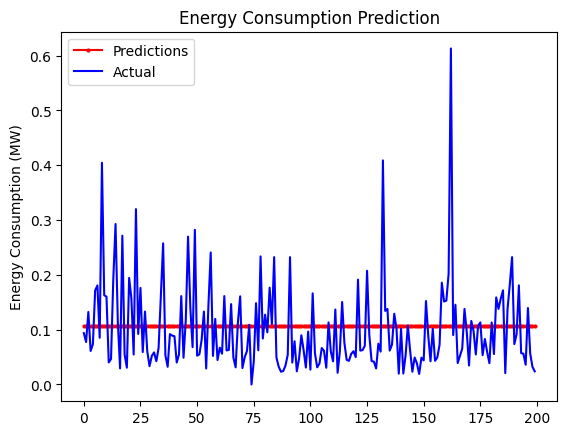

In [90]:
from sklearn.decomposition import PCA
from scipy import stats
reduced_dim = 3
print(X.size(dim=0))
print(X.size(dim=1))
print(X.size(dim=2))
X_pca = torch.zeros(size = (X.shape[0], X.shape[1], reduced_dim))
out = None
ind = 0
print(X_pca.shape)
for ind in range(X.shape[0]):
    pca = PCA(n_components = reduced_dim)
    norm = stats.zscore(X[ind], axis=1)
    pca.fit(norm)
    # print(pca.transform(X[ind, :, :]))
    X_pca[ind] = torch.from_numpy(pca.transform(norm))

train_seq, test_seq, valid_seq = divide_sequences(X_pca, Y)
gru_model = GRUModel(reduced_dim, batch_size=1024, num_layers=20, hidden_size=128, iteration_name=it_name,cnn=True,cnn_ol=15, lr=0.0001, reg=1e-6, epochs=30)
print("shape train::", train_seq[0].shape, train_seq[1].shape)
print("shape test::", test_seq[0].shape, test_seq[1].shape)
gru_model.run_model(train_seq, test_seq, valid_seq)

=== 1. Benchmarking Sequence Preprocessing: CPU vs Unaccelerated GPU vs Custom CUDA Kernel ===
shapes 15 15 torch.Size([68, 60, 6]) torch.Size([68])
[Preprocessing Benchmark] CPU: 1836.1 ms | Unaccelerated GPU: 37.6 ms | Custom CUDA: 28.2 ms
Total Preprocessing Time (15 tracks):
  CPU (.iloc loop): 1836.11 ms
  Unaccelerated GPU: 37.61 ms
  Custom CUDA Kernel: 28.17 ms
  CPU / Unaccelerated GPU: 48.8x
  CPU / Custom CUDA Kernel: 65.2x
Train shape: torch.Size([2146, 60, 6]), Test shape: torch.Size([269, 60, 6])

=== 2. Training GRU Model with Per-Epoch Latency Profiling ===
Epoch 01/15 | Train Loss: 0.000334 (0.179s) | Val Loss: 0.000164 (0.012s)
Epoch 02/15 | Train Loss: 0.000186 (0.093s) | Val Loss: 0.000129 (0.006s)
Epoch 03/15 | Train Loss: 0.000156 (0.074s) | Val Loss: 0.000102 (0.006s)
Epoch 04/15 | Train Loss: 0.000135 (0.065s) | Val Loss: 0.000094 (0.004s)
Epoch 05/15 | Train Loss: 0.000112 (0.062s) | Val Loss: 0.000099 (0.003s)
Epoch 06/15 | Train Loss: 0.000101 (0.049s) | Val 

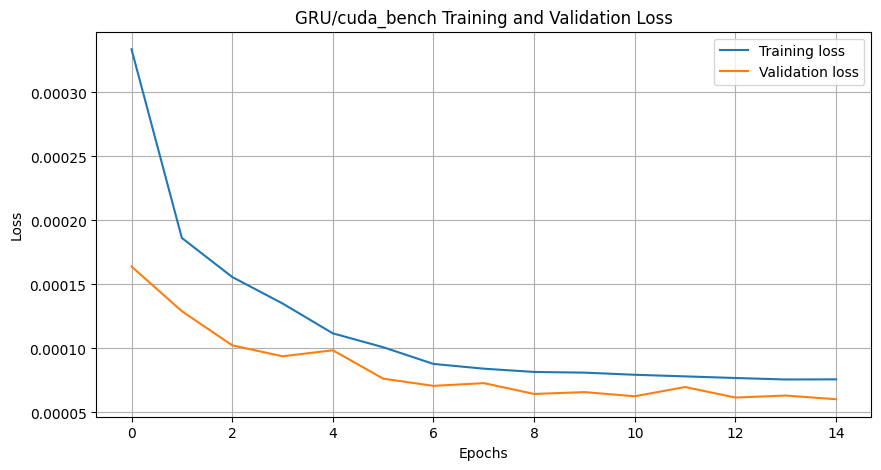

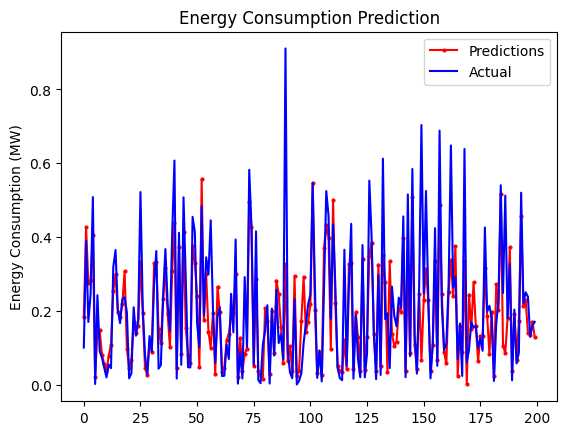


=== 3. Rendering Acceleration & Performance Dashboard ===


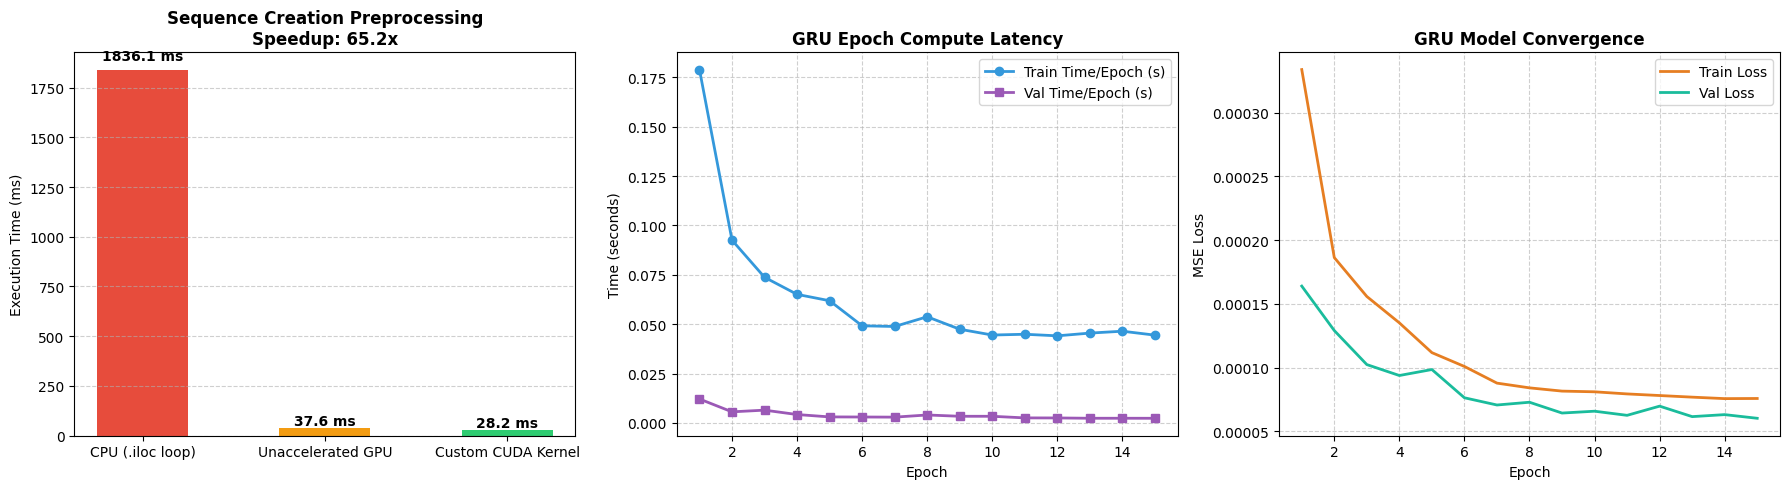

In [91]:
## CUDA vs CPU Benchmark, Model Training & Latency Dashboard
print("=== 1. Benchmarking Sequence Preprocessing: CPU vs Unaccelerated GPU vs Custom CUDA Kernel ===")
sample_ids = all_columns_present_id_list[:15]  # Benchmark on 15 tracks
X_bench, y_bench, _, cpu_prep_ms, gpu_unaccelerated_prep_ms, cuda_prep_ms = read_data(sample_ids, normalised=True, benchmark=True)
cuda_benchmark_available = _CUDA_AVAILABLE and torch.cuda.is_available()

print(f"Total Preprocessing Time (15 tracks):")
print(f"  CPU (.iloc loop): {cpu_prep_ms:.2f} ms")
if cuda_benchmark_available:
    print(f"  Unaccelerated GPU: {gpu_unaccelerated_prep_ms:.2f} ms")
    print(f"  Custom CUDA Kernel: {cuda_prep_ms:.2f} ms")
    print(f"  CPU / Unaccelerated GPU: {cpu_prep_ms / max(gpu_unaccelerated_prep_ms, 1e-4):.1f}x")
    print(f"  CPU / Custom CUDA Kernel: {cpu_prep_ms / max(cuda_prep_ms, 1e-4):.1f}x")
else:
    print("  Unaccelerated GPU: unavailable")
    print("  Custom CUDA Kernel: unavailable (CPU fallback used)")

# Split sequences
train_seq, test_seq, valid_seq = divide_sequences(X_bench, y_bench)
feature_len = train_seq[0].shape[2]
print(f"Train shape: {train_seq[0].shape}, Test shape: {test_seq[0].shape}")

print("\n=== 2. Training GRU Model with Per-Epoch Latency Profiling ===")
gru_model_timed = GRUModel(feature_len, batch_size=128, num_layers=2, hidden_size=64, iteration_name="cuda_bench", cnn=False, lr=0.001, reg=1e-6, epochs=15)
gru_model_timed.run_model(train_seq, test_seq, valid_seq)

print("\n=== 3. Rendering Acceleration & Performance Dashboard ===")
if cuda_benchmark_available:
    plot_cuda_comparison_dashboard(cpu_prep_ms, gpu_unaccelerated_prep_ms, cuda_prep_ms, gru_model_timed, model_name="GRU")
else:
    print("CUDA comparison dashboard skipped because the compiled extension is unavailable.")
